# Dataset splits and score distributions

Prepare the MHC-I binding peptides data and inspect the distributions of measured scores in the training, validation, and test splits.

In [1]:
# Prepare the data splits and inspect the distribution of measured scores for MHC-I binding peptides.
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import warnings
warnings.filterwarnings("ignore")

import matplotlib as mpl
mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['axes.unicode_minus'] = False

#### Data split

Split the data into training, validation, and test sets at a ratio of 0.8 : 0.1 : 0.1.

## Load and inspect the data

In [2]:
# Load the wsMOQA data.
plm_data = "...\\pLM-bVAE\\reproduction_paper\\data\\"
pep_data = pd.read_csv(plm_data + "raw_data\\MHCIpeptide_bdata.20130222.mhci.txt", sep="\t")

In [3]:
# Select HLA-A*02:01 binding peptides.
pep_data_filtered = pep_data[pep_data['mhc'] == "HLA-A*02:01"].reset_index(drop=True)  


In [4]:
pep_data_filtered 

,species,mhc,peptide_length,sequence,inequality,meas
0,human,HLA-A*02:01,8,ILGFVFTL,=,1.225423
1,human,HLA-A*02:01,8,FLGRIWPS,=,2.000000
2,human,HLA-A*02:01,8,FLGKIWPS,=,4.000000
3,human,HLA-A*02:01,8,FLGKIWSS,=,8.000000
4,human,HLA-A*02:01,8,GLAVAMEV,=,31.808753
...,...,...,...,...,...,...
12155,human,HLA-A*02:01,15,EISTNIRQAGVQYSR,>,178571.428600
12156,human,HLA-A*02:01,15,IRQAGVQYSRADEEQ,>,178571.428600
12157,human,HLA-A*02:01,17,QFLKFSLPFPFLYKFLL,=,20681.845230
12158,human,HLA-A*02:01,18,PLMGGAYIAFPTSCHMFI,=,13161.358710


In [5]:
# Check for duplicate sequences.
print(pep_data_filtered['sequence'].duplicated().sum())

0


In [6]:
# Count rows with meas equal to one.
print(pep_data_filtered[pep_data_filtered['meas'] == 1].shape[0])

409


In [7]:
# Apply a log transformation to measured values.
pep_data_filtered['log_meas'] = np.log(pep_data_filtered['meas'])

In [8]:
pep_data_filtered

,species,mhc,peptide_length,sequence,inequality,meas,log_meas
0,human,HLA-A*02:01,8,ILGFVFTL,=,1.225423,0.203286
1,human,HLA-A*02:01,8,FLGRIWPS,=,2.000000,0.693147
2,human,HLA-A*02:01,8,FLGKIWPS,=,4.000000,1.386294
3,human,HLA-A*02:01,8,FLGKIWSS,=,8.000000,2.079442
4,human,HLA-A*02:01,8,GLAVAMEV,=,31.808753,3.459742
...,...,...,...,...,...,...,...
12155,human,HLA-A*02:01,15,EISTNIRQAGVQYSR,>,178571.428600,12.092744
12156,human,HLA-A*02:01,15,IRQAGVQYSRADEEQ,>,178571.428600,12.092744
12157,human,HLA-A*02:01,17,QFLKFSLPFPFLYKFLL,=,20681.845230,9.937012
12158,human,HLA-A*02:01,18,PLMGGAYIAFPTSCHMFI,=,13161.358710,9.485040


In [9]:
# Check for duplicate sequences.
print(pep_data_filtered['sequence'].duplicated().sum())

0


In [10]:
# Inspect the minimum and maximum sequence lengths.
max_length = pep_data_filtered['sequence'].apply(lambda x: len(x)).max()
min_length = pep_data_filtered['sequence'].apply(lambda x: len(x)).min()
print(f"Maximum sequence length: {max_length}, Minimum sequence length: {min_length}")

Maximum sequence length: 30, Minimum sequence length: 8


In [11]:
# Select and rename the sequence and log-transformed score columns.
pep_data_filtered_clean = pep_data_filtered[['sequence', 'log_meas']].rename(columns={'sequence': 'seq', 'log_meas': 'score'})

In [12]:
pep_data_filtered_clean

,seq,score
0,ILGFVFTL,0.203286
1,FLGRIWPS,0.693147
2,FLGKIWPS,1.386294
3,FLGKIWSS,2.079442
4,GLAVAMEV,3.459742
...,...,...
12155,EISTNIRQAGVQYSR,12.092744
12156,IRQAGVQYSRADEEQ,12.092744
12157,QFLKFSLPFPFLYKFLL,9.937012
12158,PLMGGAYIAFPTSCHMFI,9.485040


In [13]:
# Count consecutive repeats in peptide sequences.
from collections import Counter
def count_consecutive_repeats(sequence):
    if not sequence:
        return 0
    count = 1
    max_count = 1
    for i in range(1, len(sequence)):
        if sequence[i] == sequence[i-1]:
            count += 1
            max_count = max(max_count, count)
        else:
            count = 1
    return max_count

print(pep_data_filtered_clean['seq'].apply(count_consecutive_repeats).value_counts())

seq
1    6573
2    5023
3     470
4      75
5      13
6       4
7       1
8       1
Name: count, dtype: int64


In [14]:
# Count sequences by length in ascending order.
pep_data_filtered_clean['seq'].apply(len).value_counts().sort_index()

seq
8      167
9     9051
10    2753
11     139
12      10
13      15
14      11
15      11
17       1
18       1
30       1
Name: count, dtype: int64

#### Random data split

#### Training data for bVAE and pLM-bVAE

In [15]:
# Shuffle the peptide data.
pep_data_filtered_clean_shuffled = pep_data_filtered_clean.sample(frac=1, random_state=42).reset_index(drop=True)

# Split the shuffled data into training, validation, and test sets at a ratio of 0.8:0.1:0.1.
train_size = int(0.8 * len(pep_data_filtered_clean_shuffled))
dev_size = int(0.1 * len(pep_data_filtered_clean_shuffled))
pep_train = pep_data_filtered_clean_shuffled[:train_size]
pep_dev = pep_data_filtered_clean_shuffled[train_size:train_size + dev_size]
pep_test = pep_data_filtered_clean_shuffled[train_size + dev_size:]

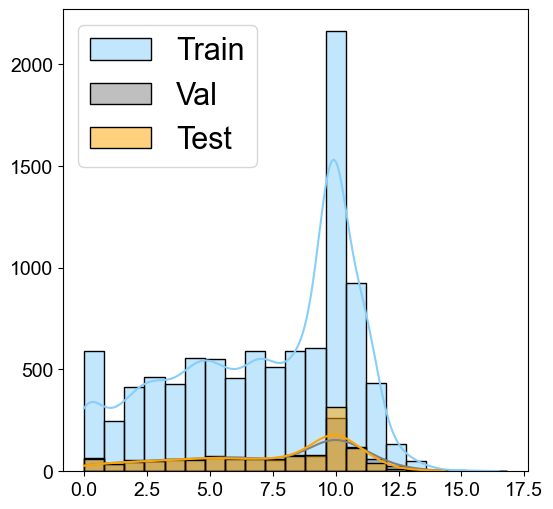

In [16]:
# Inspect the score distributions in the three splits.
plt.figure(figsize=(6, 6))

bin_width = 0.8

# Find the combined score range across the splits.
all_scores = pd.concat([pep_train["score"], pep_dev["score"], pep_test["score"]])

# Align bin boundaries to multiples of the bin width.
bin_min = np.floor(all_scores.min() / bin_width) * bin_width
bin_max = np.ceil(all_scores.max() / bin_width) * bin_width

# Use common bins for the three splits.
common_bins = np.arange(bin_min, bin_max + bin_width, bin_width)

sns.histplot(pep_train["score"], bins=common_bins, color="lightskyblue", kde=True, label="Train", alpha=0.5)
sns.histplot(pep_dev["score"], bins=common_bins, color="gray", kde=True, label="Val", alpha=0.5)
sns.histplot(pep_test["score"], bins=common_bins, color="orange", kde=True, label="Test", alpha=0.5)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.xlabel("")
plt.ylabel("")
plt.legend(fontsize=22)
plt.show()

In [17]:
# Extract the sequence column.
pep_train_seq = pep_train["seq"]
pep_dev_seq = pep_dev["seq"]
pep_test_seq = pep_test["seq"]

# Check for duplicates within each split.
print(pep_train_seq.shape[0], pep_dev_seq.shape[0], pep_test_seq.shape[0])

# Check for overlapping sequences between splits.
print(set(pep_train_seq) & set(pep_dev_seq), set(pep_train_seq) & set(pep_test_seq), set(pep_dev_seq) & set(pep_test_seq))

# Check the split sizes and proportions.
pep_train_seq.shape[0] / pep_data_filtered_clean_shuffled.shape[0], pep_dev_seq.shape[0] / pep_data_filtered_clean_shuffled.shape[0], pep_test_seq.shape[0] / pep_data_filtered_clean_shuffled.shape[0]

9728 1216 1216
set() set() set()


(0.8, 0.1, 0.1)